In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd

from google.colab import drive

### Estimación de Fermi

En una aproximación inicial suponemos un módelo de captura basada en puestos de avanzada, es decir, puestos fijos donde nuestro equipo estara capturando activamente mosquítos durante un periodo de tiempo determinado. Por tanto el número de capturas será establecido como la suma de las capturas totales realizadas en cada puesto durante el intervalo de tiempo establecido

$$ N = \sum_i^M n_i$$

siendo $N$ el número de capturas y $n_i$ las capturas en el puesto i-ésimo. Las capturas en el puesto i-ésimo se pueden a su vez descomponer como una razon de capturas por el tiempo de captura, es decir

$$ n_i = H \times v_i  $$

$H$ se refiere al número de horas de captura y $v_i$ es la velocidad de capturas por hora. Suponiendo de modo simplificado ciertos puestos equivalentes, es decir con misma velocidad de capturas

$$ N = \sum_n P_n H v_n $$

donde $P_n$ es el número de puestos equivalentes de la clase $n$.

En un módelo un poco más realista, suponemos que en realidad el número de capturas por puesto es una variable aleatoria de tipo Poisson, lo cual tiene mucho sentido por el tipo de experimento que estamos realizando, es decir cúal es el número de capturas que esperamos en un intervalo de tiempo $H$ dado una cantidad media de capturas por hora $\lambda$. Para realizar nuestra estimación empleando este modelo podemos emplear python y generar números aleatorios que sigan la distribución deseada (aproximada) y determinar la media y la desviación estandar tras tantas capturas.

Ambos modelos se pueden extender a capturas totales en un número $D$ de días de capturas.

Como hipotesis de nuestro modelo, supondremos dos tipos de sitio, Interiores (referentes a capturar dentro de una vivienda) y Exteriores, capturar en el exterior de una casa. Suponemos que la presencia de humanos a las horas de la noche aumentara la cantidad de capturas en el interior respecto al exterior. Así pues para el primer módelo

$$ N = D \times H ( P_Iv_I + P_E v_E ) $$

supondremos un

y para el segundo

$$ N = \sum_d^D ( n^{(I)}_d + n^{(E)}_d ) $$

donde $d$ es el día, $n^{(I)}$ es un entero de Poisson con media $\lambda_I = 2 \times H$ y $n^{(E)}$ es otro entero de Poisson con media $\lambda_E = 1 \times H$. Suponiendo una situación bastante pesimista, con una tasa de captura de 2 y 1 mosquito respectivamente de media por hora.

### Estimación Númerica

Suponiendo que $H = 6$ y $D = 4$ y 3 puestos de cada tipo:

1) Primer Modelo: Suponiendo entonces 2 mosquitos por hora en interior y 1 por hora en exterior el primero modelo predice que se espera un total de $N = 6 \times 4 \times 3 \times (1 + 2) = 216$

2) Segundo Modelo: El segundo modelo tras $10.000$ runs entrego estas predicciones

| Estadístico | Columna 1 | Columna 2 | Columna 3 |
| :--- | :---: | :---: | :---: |
| **count** | 10000.000000 | 10000.000000 | 10000.000000 |
| **mean** | 143.987800 | 71.921600 | 215.909400 |
| **std** | 12.157526 | 8.602724 | 14.996456 |
| **min** | 103.000000 | 42.000000 | 159.000000 |
| **25%** | 136.000000 | 66.000000 | 206.000000 |
| **50%** | 144.000000 | 72.000000 | 216.000000 |
| **75%** | 152.000000 | 78.000000 | 226.000000 |
| **max** | 194.000000 | 110.000000 | 282.000000 |



In [ ]:
import numpy as np
import pandas as pd

# Parámetros del modelo
M = 10_000  # Número de simulaciones
noches = 4
horas_por_noche = 6

puestos_interior = 3
media_interior = 2.0  # m_r

puestos_exterior = 3
media_exterior = 1.0  # m_c

# Medias consolidadas para toda la noche (6 horas)
media_noche_interior = media_interior * horas_por_noche
media_noche_exterior = media_exterior * horas_por_noche

# Listas para almacenar los datos detallados de cada simulación
datos_simulacion = []

# Ejecutar la simulación M veces
for sim_id in range(M):
    capturas_por_noche_int = np.zeros(noches)
    capturas_por_noche_ext = np.zeros(noches)

    for noche in range(noches):
        # Simular directamente el total de la noche (suma de 6 eventos de Poisson de 1 hora)
        capturas_int = np.random.poisson(media_noche_interior, size=puestos_interior).sum()
        capturas_ext = np.random.poisson(media_noche_exterior, size=puestos_exterior).sum()

        capturas_por_noche_int[noche] = capturas_int
        capturas_por_noche_ext[noche] = capturas_ext

    # Crear registro para la simulación actual
    registro = {
        'Simulacion': sim_id,
        'Interior_Total': capturas_por_noche_int.sum(),
        'Exterior_Total': capturas_por_noche_ext.sum(),
        'N_Total': capturas_por_noche_int.sum() + capturas_por_noche_ext.sum()
    }

    # Agregar datos específicos por noche
    for noche in range(noches):
        registro[f'Noche_{noche+1}_Interior'] = capturas_por_noche_int[noche]
        registro[f'Noche_{noche+1}_Exterior'] = capturas_por_noche_ext[noche]
        registro[f'Noche_{noche+1}_Total'] = capturas_por_noche_int[noche] + capturas_por_noche_ext[noche]

    datos_simulacion.append(registro)

# Guardar todo en un DataFrame
df_resultados = pd.DataFrame(datos_simulacion)

# Mostrar estadísticas descriptivas principales
print("Estadísticas de la simulación consolidadas:")
display(df_resultados[['Interior_Total', 'Exterior_Total', 'N_Total']].describe())

print("\nPrimeras filas del DataFrame generado (df_resultados):")
display(df_resultados.head())

Estadísticas de la simulación consolidadas:


,Interior_Total,Exterior_Total,N_Total
count,10000.000000,10000.000000,10000.000000
mean,143.987800,71.921600,215.909400
std,12.157526,8.602724,14.996456
min,103.000000,42.000000,159.000000
25%,136.000000,66.000000,206.000000
50%,144.000000,72.000000,216.000000
75%,152.000000,78.000000,226.000000
max,194.000000,110.000000,282.000000



Primeras filas del DataFrame generado (df_resultados):


,Simulacion,Interior_Total,Exterior_Total,N_Total,Noche_1_Interior,Noche_1_Exterior,Noche_1_Total,Noche_2_Interior,Noche_2_Exterior,Noche_2_Total,Noche_3_Interior,Noche_3_Exterior,Noche_3_Total,Noche_4_Interior,Noche_4_Exterior,Noche_4_Total
0,0,149.0,66.0,215.0,28.0,15.0,43.0,37.0,21.0,58.0,43.0,15.0,58.0,41.0,15.0,56.0
1,1,138.0,78.0,216.0,33.0,22.0,55.0,35.0,14.0,49.0,31.0,27.0,58.0,39.0,15.0,54.0
2,2,131.0,72.0,203.0,42.0,18.0,60.0,31.0,19.0,50.0,29.0,14.0,43.0,29.0,21.0,50.0
3,3,128.0,71.0,199.0,38.0,20.0,58.0,25.0,18.0,43.0,35.0,21.0,56.0,30.0,12.0,42.0
4,4,119.0,63.0,182.0,26.0,15.0,41.0,40.0,17.0,57.0,23.0,16.0,39.0,30.0,15.0,45.0


In [ ]:
N_modelo1 = 4*6*3*( 2 + 1 )
print(N_modelo1)

216


# **2.1. Propuesta de hoja de campo**
Para registrar las capturas de mosquitos, proponemos diseñar una hoja de campo que incluya las siguientes variables:
- Puesto: lugar donde se realiza la captura, indicando si es interior o exterior.
- Hora: momento en que se captura el mosquito.
- Sexo: macho o hembra.
- Mosquito: especie identificada, si es posible.
- Día: fecha en la que se realiza la captura.
- Vivienda: identificación de la vivienda donde se encuentra el puesto.
- Condiciones climáticas: registrar si hay lluvia durante la captura.
Consideramos que estas variables permitirían conocer no solo la cantidad de mosquitos capturados, sino también identificar posibles diferencias según el lugar, la hora y las condiciones ambientales.

Además, sería importante registrar las horas efectivas de trabajo de cada puesto, incluso cuando no se capture ningún mosquito. Esto permitiría calcular tasas de captura y realizar comparaciones más justas entre diferentes días y lugares, evitando confundir una menor cantidad de mosquitos con un menor esfuerzo de muestreo.

puesto, hora,  sexo, mosquito, día

In [ ]:
# 1. Montar Google Drive
drive.mount('/content/drive')

# AJUSTA ESTA RUTA a la carpeta de tu Drive donde tengas el archivo
ruta_archivo = '/content/drive/MyDrive/Colab Notebooks/Fiscom/occurrence.txt'
# ruta_archivo = '/content/drive/MyDrive/Ensayo_nn/occurrence.txt'

# 2. Leer el archivo original (separado por tabulaciones)
df_raw = pd.read_csv(ruta_archivo, sep='\t', encoding='utf-8', low_memory=False)

# 3. Imprimir todos los títulos de las columnas originales
print(f"=== TOTAL DE COLUMNAS ORIGINALES ({len(df_raw.columns)}) ===")
for idx, col in enumerate(df_raw.columns, 1):
    print(f"{idx:02d}. {col}")

# 4. Seleccionar únicamente las columnas relevantes para análisis estadístico
# Descartamos columnas constantes (país, reino, clase, sexo=Hembra, lifeStage=Adulto, etc.)
columnas_relevantes = [
    'id',
    'eventID',
    'parentEventID',      # Conglomerado / punto específico (ej. Chete1, Chete2)
    'eventDate',          # Fecha o rango de fechas de captura
    'eventTime',          # Horario de muestreo (ej. 17:00 a 07:00 o 05:00)
    'year',
    'month',
    'habitat',            # Sitio de captura (En domicilio / intradomicilio / peridomicilio)
    'samplingProtocol',   # Método (ej. Aspirador bucal | Colecta con cebo humano)
    'samplingEffort',     # Horas por noche y cantidad de noches
    'stateProvince',      # Departamento
    'municipality',       # Municipio (Timbiquí, Guapi, Santa Bárbara)
    'locality',           # Localidad estandarizada (ej. Cheté)
    'verbatimLocality',   # Sub-localidad específica (ej. Chete 1, Chete 2)
    'minimumElevationInMeters',
    'decimalLatitude',
    'decimalLongitude',
    'scientificName',     # Especie (An. albimanus, An. neivai, An. apicimacula)
    'individualCount'     # Variable respuesta: Número de mosquitos capturados
]

df_clean = df_raw[columnas_relevantes].copy()

# 5. Transformación y limpieza para estudio estadístico
# 5.1 Extraer horas por noche y número de noches desde 'samplingEffort' (ej. "14 h por noche, 3 noches")
esfuerzo_extraido = df_clean['samplingEffort'].str.extract(r'(\d+)\s*h por noche,\s*(\d+)\s*noche')
df_clean['horas_por_noche'] = pd.to_numeric(esfuerzo_extraido[0], errors='coerce')
df_clean['noches_muestreo'] = pd.to_numeric(esfuerzo_extraido[1], errors='coerce')
df_clean['esfuerzo_total_horas'] = df_clean['horas_por_noche'] * df_clean['noches_muestreo']

# 5.2 Calcular tasas entomológicas estandarizadas (clave para comparar meses con distinto esfuerzo)
df_clean['mosquitos_por_noche'] = df_clean['individualCount'] / df_clean['noches_muestreo']
df_clean['mosquitos_por_hora'] = df_clean['individualCount'] / df_clean['esfuerzo_total_horas']

# 5.3 Separar 'eventDate' en fecha de inicio y fin (ya que vienen como rangos YYYY-MM-DD/YYYY-MM-DD)
fechas = df_clean['eventDate'].str.split('/', expand=True)
df_clean['fecha_inicio'] = pd.to_datetime(fechas[0], format='%Y-%m-%d', errors='coerce')
df_clean['fecha_fin'] = pd.to_datetime(fechas[1].fillna(fechas[0]), format='%Y-%m-%d', errors='coerce')

# Rellenar posibles valores faltantes en 'month' y 'year' usando 'fecha_inicio'
df_clean['year'] = df_clean['year'].fillna(df_clean['fecha_inicio'].dt.year).astype('Int64')
df_clean['month'] = df_clean['month'].fillna(df_clean['fecha_inicio'].dt.month).astype('Int64')

# 6. Filtrar el subconjunto de datos específico para la localidad de Cheté
# Usamos str.contains por seguridad ante posibles variaciones de tildes en el resto del archivo
df_chete = df_clean[df_clean['locality'].str.contains('Chet', case=False, na=False)].copy()

print("\n=== RESUMEN DEL DATASET DE CHETÉ ===")
print(f"Total de registros (eventos/especie) en Cheté: {len(df_chete)}")
print(f"Total de mosquitos capturados en Cheté: {df_chete['individualCount'].sum()}")
print("\nDistribución por sub-localidad (verbatimLocality) y especie en Cheté:")
resumen_chete = df_chete.groupby(['verbatimLocality', 'scientificName']).agg(
    eventos=('id', 'count'),
    total_mosquitos=('individualCount', 'sum'),
    promedio_por_noche=('mosquitos_por_noche', 'mean'),
    desv_est_por_noche=('mosquitos_por_noche', 'std')
).reset_index()
display(resumen_chete)

print("\n=== PRIMERAS FILAS DEL DATAFRAME DE CHETÉ ===")
display(df_chete.head(10))

# 7. Guardar los nuevos DataFrames listos para análisis en tu Drive
df_clean.to_csv('/content/drive/MyDrive/anopheles_limpio_completo.csv', index=False, encoding='utf-8')
df_chete.to_csv('/content/drive/MyDrive/anopheles_chete.csv', index=False, encoding='utf-8')
print("\nArchivos CSV guardados exitosamente en tu Google Drive.")

Mounted at /content/drive
=== TOTAL DE COLUMNAS ORIGINALES (68) ===
01. id
02. type
03. modified
04. language
05. institutionID
06. institutionCode
07. datasetName
08. basisOfRecord
09. occurrenceID
10. recordedBy
11. recordedByID
12. individualCount
13. sex
14. lifeStage
15. occurrenceStatus
16. preparations
17. occurrenceRemarks
18. eventID
19. parentEventID
20. eventDate
21. eventTime
22. year
23. month
24. verbatimEventDate
25. habitat
26. samplingProtocol
27. samplingEffort
28. locationID
29. continent
30. country
31. countryCode
32. stateProvince
33. county
34. municipality
35. locality
36. verbatimLocality
37. minimumElevationInMeters
38. maximumElevationInMeters
39. verbatimElevation
40. decimalLatitude
41. decimalLongitude
42. geodeticDatum
43. verbatimLatitude
44. verbatimLongitude
45. verbatimCoordinateSystem
46. verbatimSRS
47. georeferencedBy
48. georeferenceRemarks
49. identifiedBy
50. identifiedByID
51. dateIdentified
52. identificationReferences
53. scientificName
54. h

,verbatimLocality,scientificName,eventos,total_mosquitos,promedio_por_noche,desv_est_por_noche
0,Chete 1,Anopheles albimanus,22,5964,79.815909,46.243811
1,Chete 1,Anopheles apicimacula,4,4,0.279167,0.065793
2,Chete 1,Anopheles neivai,14,79,1.541667,1.612170
3,Chete 2,Anopheles albimanus,23,1323,19.166667,15.164773
4,Chete 2,Anopheles apicimacula,1,1,1.000000,NaN
5,Chete 2,Anopheles neivai,13,47,1.102564,0.687314



=== PRIMERAS FILAS DEL DATAFRAME DE CHETÉ ===


,id,eventID,parentEventID,eventDate,eventTime,year,month,habitat,samplingProtocol,samplingEffort,...,decimalLongitude,scientificName,individualCount,horas_por_noche,noches_muestreo,esfuerzo_total_horas,mosquitos_por_noche,mosquitos_por_hora,fecha_inicio,fecha_fin
38,INS:ProyectoVectorLink:Anopheles-39,Chete1-01,Chete1,2021-01-20/2021-01-27,17:00:00/07:00:00,2021,1,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 3 noches",...,-77.623091,Anopheles albimanus,201,14,3,42,67.000000,4.785714,2021-01-20,2021-01-27
40,INS:ProyectoVectorLink:Anopheles-41,Chete1-01,Chete1,2021-01-20,17:00:00/07:00:00,2021,1,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 1 noche",...,-77.623091,Anopheles neivai,1,14,1,14,1.000000,0.071429,2021-01-20,2021-01-20
45,INS:ProyectoVectorLink:Anopheles-46,Chete2-01,Chete2,2021-01-21/2021-01-28,17:00:00/07:00:00,2021,1,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 2 noches",...,-77.624947,Anopheles albimanus,123,14,2,28,61.500000,4.392857,2021-01-21,2021-01-28
60,INS:ProyectoVectorLink:Anopheles-61,Chete2-01,Chete2,2021-01-28,17:00:00/07:00:00,2021,1,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 1 noche",...,-77.624947,Anopheles apicimacula,1,14,1,14,1.000000,0.071429,2021-01-28,2021-01-28
61,INS:ProyectoVectorLink:Anopheles-62,Chete2-01,Chete2,2021-01-28,17:00:00/07:00:00,2021,1,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 1 noche",...,-77.624947,Anopheles neivai,2,14,1,14,2.000000,0.142857,2021-01-28,2021-01-28
77,INS:ProyectoVectorLink:Anopheles-78,Chete1-02,Chete1,2021-02-03/2021-02-10,17:00:00/07:00:00,2021,2,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 2 noches",...,-77.623091,Anopheles albimanus,78,14,2,28,39.000000,2.785714,2021-02-03,2021-02-10
85,INS:ProyectoVectorLink:Anopheles-86,Chete2-02,Chete2,2021-02-04/2021-02-11,17:00:00/07:00:00,2021,2,En domicilio,Aspirador bucal | Colecta con cebo humano,"14 h por noche, 2 noches",...,-77.624947,Anopheles albimanus,102,14,2,28,51.000000,3.642857,2021-02-04,2021-02-11
150,INS:ProyectoVectorLink:Anopheles-151,Chete1-03,Chete1,2021-04-13/2021-04-26,17:00:00/05:00:00,2021,4,En domicilio,Aspirador bucal | Colecta con cebo humano,"12 h por noche, 3 noches",...,-77.623091,Anopheles albimanus,272,12,3,36,90.666667,7.555556,2021-04-13,2021-04-26
166,INS:ProyectoVectorLink:Anopheles-167,Chete2-03,Chete2,2021-04-15/2021-04-28,17:00:00/05:00:00,2021,4,En domicilio,Aspirador bucal | Colecta con cebo humano,"12 h por noche, 3 noches",...,-77.624947,Anopheles albimanus,61,12,3,36,20.333333,1.694444,2021-04-15,2021-04-28
216,INS:ProyectoVectorLink:Anopheles-217,Chete1-04,Chete1,2021-05-03/2021-05-19,17:00:00/05:00:00,2021,5,En domicilio,Aspirador bucal | Colecta con cebo humano,"12 h por noche, 3 noches",...,-77.623091,Anopheles albimanus,160,12,3,36,53.333333,4.444444,2021-05-03,2021-05-19



Archivos CSV guardados exitosamente en tu Google Drive.


In [ ]:
df_raw['genus'].unique()

array(['Anopheles'], dtype=object)

=== ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS ===


,individualCount,horas_por_noche,noches_muestreo,esfuerzo_total_horas,mosquitos_por_noche,mosquitos_por_hora
count,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000,1502.000000
mean,152.725699,12.176431,3.353529,40.581891,45.751487,3.750806
std,242.038716,0.662222,1.128422,13.323811,69.234828,5.648269
min,1.000000,7.000000,1.000000,12.000000,0.166667,0.013889
25%,4.000000,12.000000,3.000000,36.000000,1.333333,0.111111
50%,45.000000,12.000000,4.000000,48.000000,16.000000,1.309028
75%,196.750000,12.000000,4.000000,48.000000,61.625000,5.052827
max,1595.000000,14.000000,6.000000,84.000000,502.500000,37.166667



=== MATRIZ DE CORRELACIÓN (PEARSON) ===


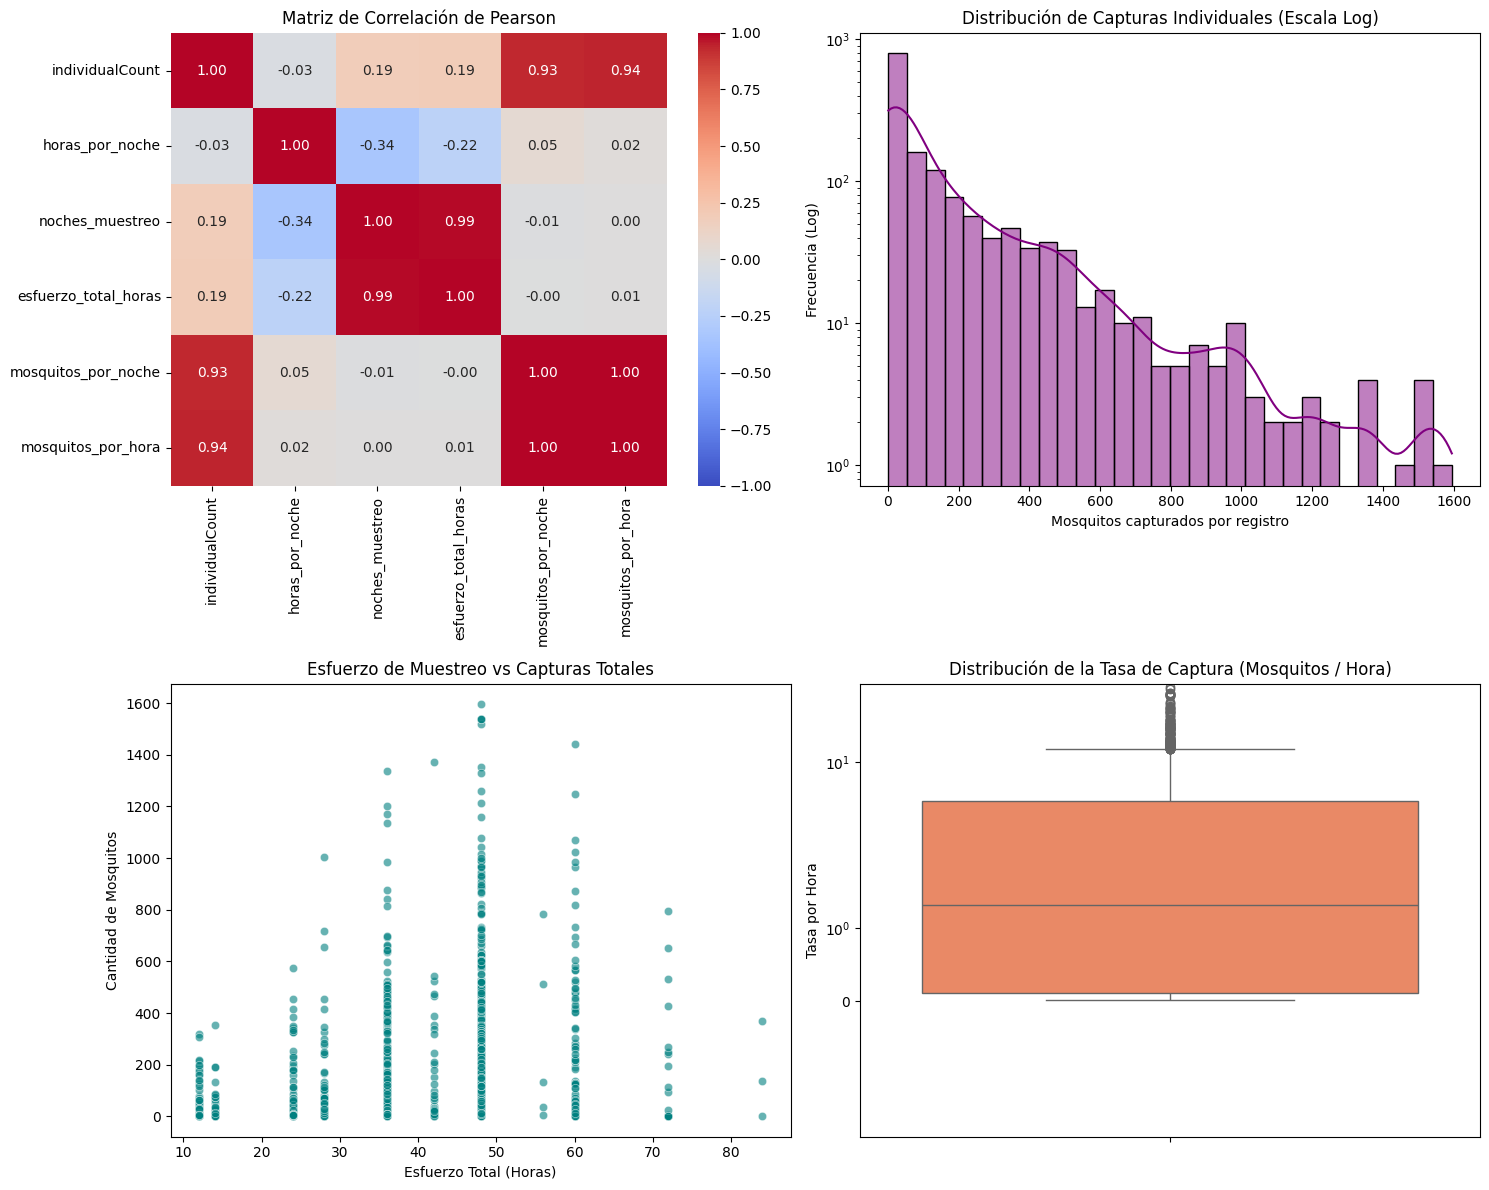

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Selección de variables numéricas clave
columnas_numericas = [
    'individualCount',
    'horas_por_noche',
    'noches_muestreo',
    'esfuerzo_total_horas',
    'mosquitos_por_noche',
    'mosquitos_por_hora'
]

# Aseguramos que los datos sean numéricos y descartamos filas con nulos en estas variables para el análisis
df_num = df_clean[columnas_numericas].dropna().copy()

print("=== ESTADÍSTICAS DESCRIPTIVAS DE LAS VARIABLES NUMÉRICAS ===")
display(df_num.describe())

# 2. Análisis de Correlación (Pearson y Spearman para relaciones no lineales)
corr_pearson = df_num.corr(method='pearson')
corr_spearman = df_num.corr(method='spearman')

print("\n=== MATRIZ DE CORRELACIÓN (PEARSON) ===")
# display(corr_pearson.round(3))

# 3. Construcción del Panel de Visualizaciones
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Gráfico 1: Mapa de calor de correlaciones
sns.heatmap(corr_pearson, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=axes[0, 0])
axes[0, 0].set_title('Matriz de Correlación de Pearson')

# Gráfico 2: Distribución del número de mosquitos capturados (Escala Logarítmica por asimetría)
sns.histplot(df_num['individualCount'], bins=30, kde=True, color='purple', ax=axes[0, 1])
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Distribución de Capturas Individuales (Escala Log)')
axes[0, 1].set_xlabel('Mosquitos capturados por registro')
axes[0, 1].set_ylabel('Frecuencia (Log)')

# Gráfico 3: Relación entre Esfuerzo Total y Capturas
sns.scatterplot(data=df_num, x='esfuerzo_total_horas', y='individualCount', alpha=0.6, color='teal', ax=axes[1, 0])
axes[1, 0].set_title('Esfuerzo de Muestreo vs Capturas Totales')
axes[1, 0].set_xlabel('Esfuerzo Total (Horas)')
axes[1, 0].set_ylabel('Cantidad de Mosquitos')

# Gráfico 4: Distribución de las Tasas de Captura por Hora
sns.boxplot(data=df_num, y='mosquitos_por_hora', color='coral', ax=axes[1, 1])
axes[1, 1].set_title('Distribución de la Tasa de Captura (Mosquitos / Hora)')
axes[1, 1].set_ylabel('Tasa por Hora')
axes[1, 1].set_yscale('symlog')  # Escala simétrica logarítmica para manejar outliers extremos

plt.tight_layout()
plt.show()

=== RESUMEN DE CAPTURAS POR LOCALIDAD Y GÉNERO ===


genus,Anopheles,Total
locality,,
Calle del Pueblo,21034,21034
Quiroga,19681,19681
Puerto Saija,16915,16915
Limones,15262,15262
San Miguel del Río,14309,14309
Mataco,14075,14075
El Carmelo,12589,12589
Coteje,12236,12236
"Santa Bárbara, El Firme",11382,11382


<Figure size 1400x700 with 0 Axes>

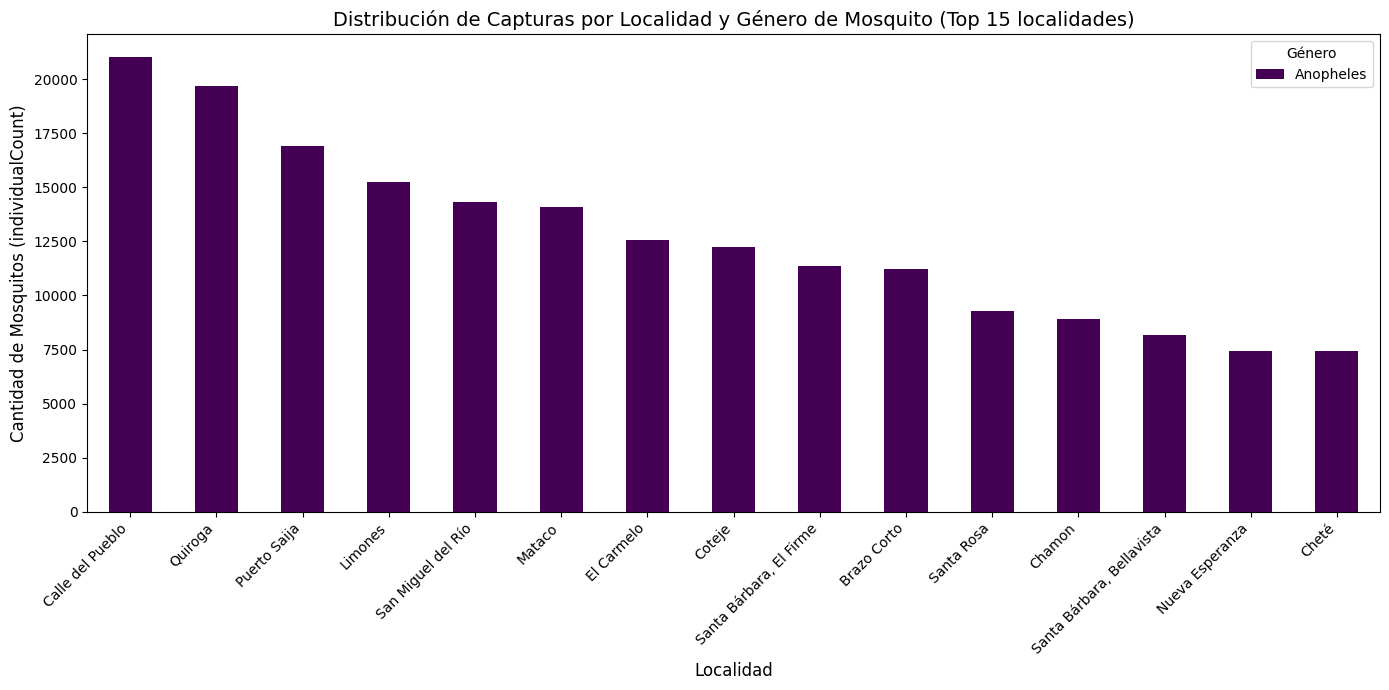

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraer el Género (primer componente de scientificName)
df_clean['genus'] = df_clean['scientificName'].str.split().str[0]

# 2. Agrupación por localidad de detección (locality) y Género de mosquito
agrupado_loc_gen = df_clean.groupby(['locality', 'genus'])['individualCount'].sum().unstack(fill_value=0)

# Añadimos totales para tener una visualización completa
agrupado_loc_gen['Total'] = agrupado_loc_gen.sum(axis=1)
agrupado_loc_gen = agrupado_loc_gen.sort_values(by='Total', ascending=False)

print("=== RESUMEN DE CAPTURAS POR LOCALIDAD Y GÉNERO ===")
display(agrupado_loc_gen)

# 3. Graficar la distribución de géneros por localidad
# Excluimos la columna 'Total' para evitar distorsiones en la visualización
grafica_datos = agrupado_loc_gen.drop(columns='Total').head(15)  # Mostramos las 15 localidades con más capturas

plt.figure(figsize=(14, 7))
grafica_datos.plot(kind='bar', stacked=True, colormap='viridis', figsize=(14, 7))

plt.title('Distribución de Capturas por Localidad y Género de Mosquito (Top 15 localidades)', fontsize=14)
plt.xlabel('Localidad', fontsize=12)
plt.ylabel('Cantidad de Mosquitos (individualCount)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Género', fontsize=10)
plt.tight_layout()
plt.show()

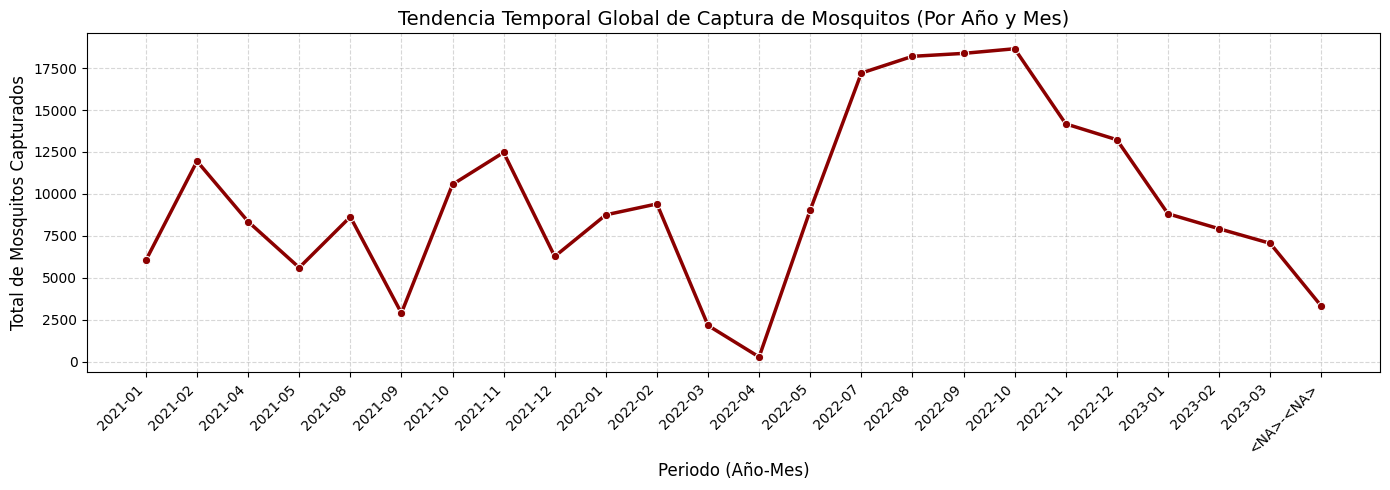

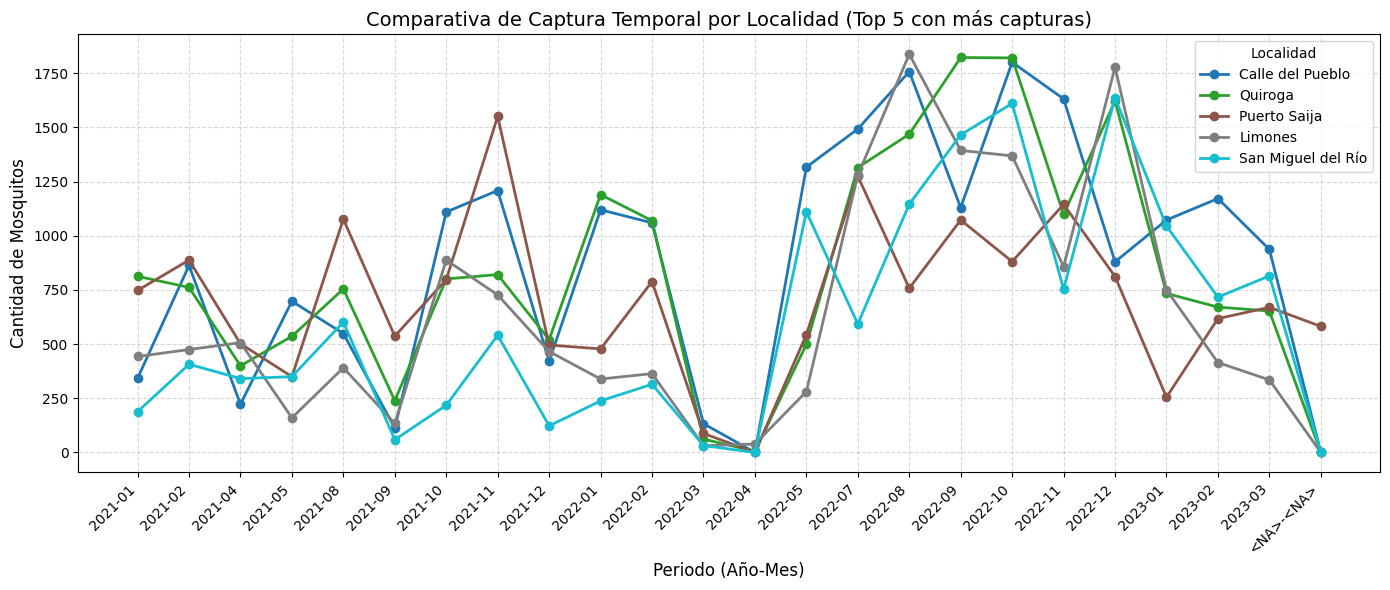

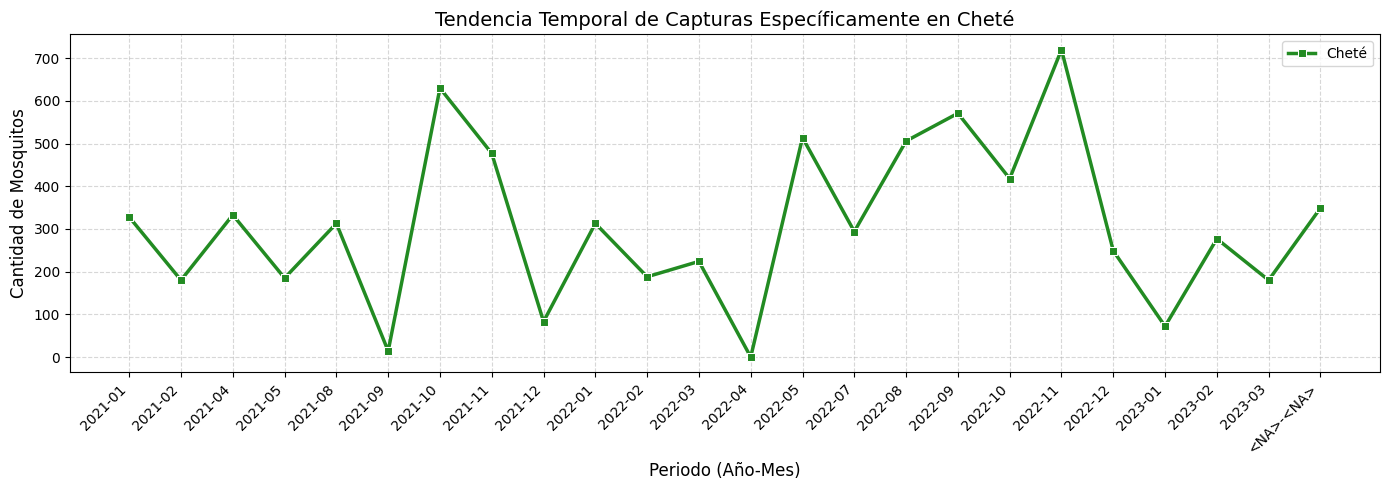

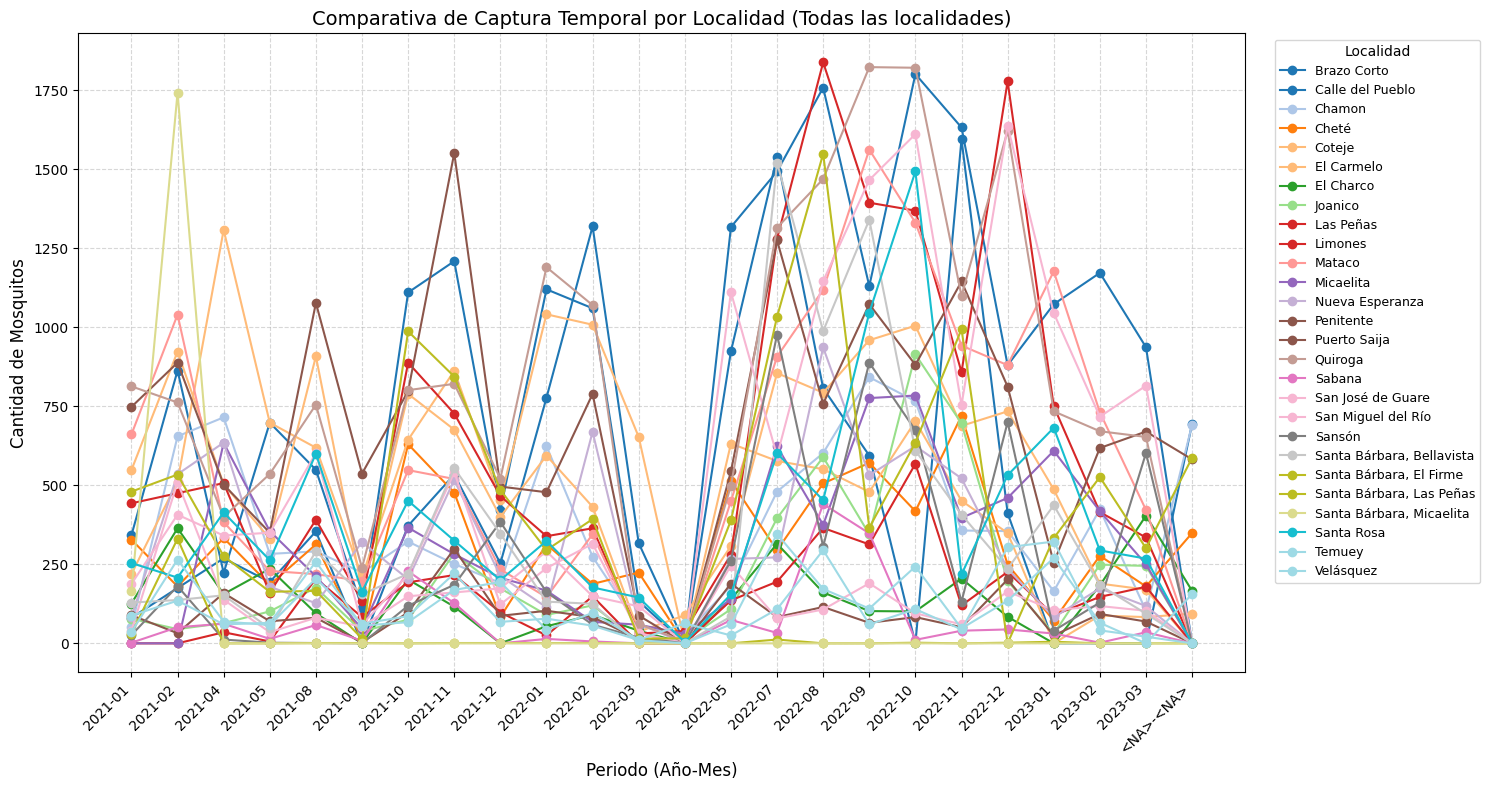

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar la estructura temporal (Año-Mes) en df_clean
df_clean['periodo'] = df_clean['year'].astype(str) + '-' + df_clean['month'].astype(str).str.zfill(2)

# Agrupar por periodo de tiempo global
temporal_global = df_clean.groupby('periodo')['individualCount'].sum().reset_index()
temporal_global = temporal_global.sort_values('periodo')

# 2. Agrupar por periodo de tiempo para todas las localidades
temporal_todas_localidades = df_clean.groupby(['periodo', 'locality'])['individualCount'].sum().unstack(fill_value=0)

# 3. Agrupar por periodo de tiempo para las localidades top y Cheté
top_num = 5
top_localidades = df_clean.groupby('locality')['individualCount'].sum().nlargest(top_num).index.tolist()
localidades_analisis = list(set(top_localidades + ['Cheté']))
df_top_y_chete = df_clean[df_clean['locality'].isin(localidades_analisis)]
temporal_comparativa = df_top_y_chete.groupby(['periodo', 'locality'])['individualCount'].sum().unstack(fill_value=0)

# === GRÁFICA 1: Tendencia Temporal Global ===
plt.figure(figsize=(14, 5))
sns.lineplot(data=temporal_global, x='periodo', y='individualCount', marker='o', color='darkred', linewidth=2.5)
plt.title('Tendencia Temporal Global de Captura de Mosquitos (Por Año y Mes)', fontsize=14)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Total de Mosquitos Capturados', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# === GRÁFICA 2: Comparativa Temporal por Localidad (Top) ===
plt.figure(figsize=(14, 6))
colormap_top = plt.get_cmap('tab10', len(top_localidades))
temporal_comparativa[top_localidades].plot(kind='line', marker='o', ax=plt.gca(), linewidth=2, colormap=colormap_top)
plt.title(f'Comparativa de Captura Temporal por Localidad (Top {top_num} con más capturas)', fontsize=14)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Cantidad de Mosquitos', fontsize=12)
plt.xticks(range(len(temporal_comparativa.index)), temporal_comparativa.index, rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Localidad', fontsize=10)
plt.tight_layout()
plt.show()

# === GRÁFICA 3: Tendencia Temporal ÚNICAMENTE para Cheté ===
plt.figure(figsize=(14, 5))
if 'Cheté' in temporal_comparativa.columns:
    sns.lineplot(data=temporal_comparativa, x=temporal_comparativa.index, y='Cheté', marker='s', color='forestgreen', linewidth=2.5, label='Cheté')
plt.title('Tendencia Temporal de Capturas Específicamente en Cheté', fontsize=14)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Cantidad de Mosquitos', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# === GRÁFICA 4: Comparativa Temporal de TODAS las localidades (Gráfico de líneas) ===
plt.figure(figsize=(15, 8))
colormap_todas = plt.get_cmap('tab20', len(temporal_todas_localidades.columns))
temporal_todas_localidades.plot(kind='line', marker='o', ax=plt.gca(), linewidth=1.5, colormap=colormap_todas)
plt.title('Comparativa de Captura Temporal por Localidad (Todas las localidades)', fontsize=14)
plt.xlabel('Periodo (Año-Mes)', fontsize=12)
plt.ylabel('Cantidad de Mosquitos', fontsize=12)
plt.xticks(range(len(temporal_todas_localidades.index)), temporal_todas_localidades.index, rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Localidad', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
df_clean['verbatimLocality'].unique()

array(['El Carmelo', 'Limones 1', 'Quiroga 2', 'Quiroga 3',
       'San José de Guare', 'Santa Rosa 1', 'Chamon', 'Joanico 1',
       'Chamoncito', 'Joanico 2', 'Limones 2', 'Sabana', 'Sansón',
       'Santa Rosa 2', 'Temuey 1', 'Temuey 2', 'Quiroga 1', 'El Firme',
       'Las Peñas', 'Micaelita', 'Bellavista', 'Chete 1', 'Mataco',
       'Calle del Pueblo 1', 'Los brazos del Saija 1', 'El Charco',
       'Chete 2', 'Los brazos del Saija 3', 'Brazo Corto', 'Coteje 1',
       'Nueva Esperanza', 'Coteje 2', 'Los brazos del Saija 2',
       'Velasquez', 'Calle del Pueblo 2', 'San Miguel del Río 1',
       'San Miguel del Río 2', 'Limones 3', 'Penitente 1', 'Penitente 2'],
      dtype=object)

# **2.2. Comparación de la hoja de campo con los datos reales**

Al explorar los datos reales del estudio, encontramos información sobre las capturas de mosquitos *Anopheles* en distintas localidades. Para nuestro análisis seleccionamos los registros de Cheté, diferenciando entre Cheté 1 y Cheté 2. Los datos incluyen la especie, cantidad de mosquitos capturados, fecha, horario general, hábitat (dentro o fuera del domicilio), método de captura y esfuerzo de muestreo, expresado en horas por noche y número de noches.

Al comparar estos registros con nuestra hoja de campo, encontramos que varias de las variables propuestas sí fueron consideradas, como el lugar, la fecha, la especie y el sexo, aunque este último aparece registrado como hembra. Sin embargo, **faltan algunos detalles que habíamos considerado importantes**, como la hora exacta de cada captura, las condiciones climáticas y la identificación individual de las viviendas.

Además, observamos que los datos agrupan capturas por evento y especie, en lugar de registrar cada mosquito individualmente. Esto permite conocer las cantidades capturadas, pero limita el análisis de cómo varían las capturas durante cada noche. Por eso, consideramos que nuestra hoja de campo podría complementar los registros existentes con información más detallada sobre las condiciones y los momentos de captura.

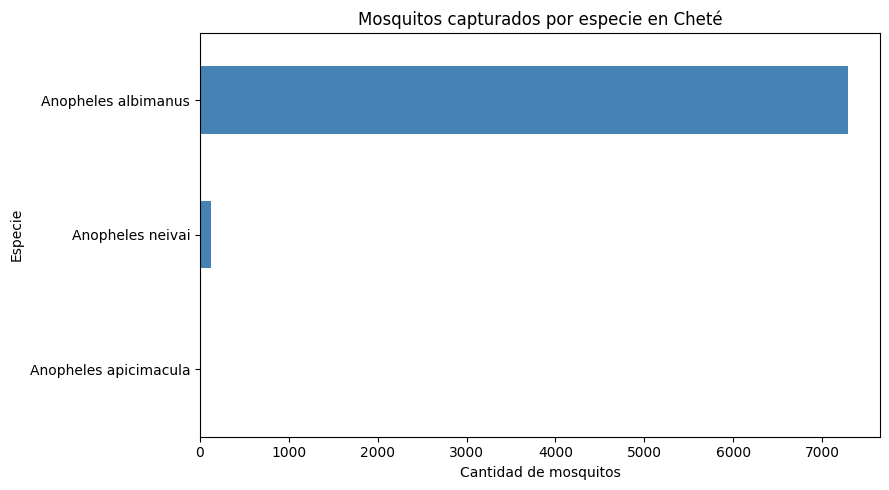

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Total de mosquitos por especie
por_especie = df_chete.groupby('scientificName')['individualCount'].sum()

plt.figure(figsize=(9, 5))
por_especie.sort_values().plot(kind='barh', color='steelblue')

plt.title('Mosquitos capturados por especie en Cheté')
plt.xlabel('Cantidad de mosquitos')
plt.ylabel('Especie')
plt.tight_layout()
plt.show()


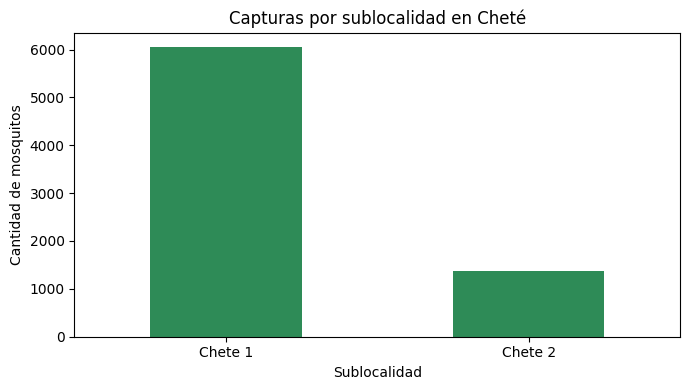

In [ ]:

# Total de mosquitos por sublocalidad
por_lugar = df_chete.groupby('verbatimLocality')['individualCount'].sum()

plt.figure(figsize=(7, 4))
por_lugar.plot(kind='bar', color='seagreen')

plt.title('Capturas por sublocalidad en Cheté')
plt.xlabel('Sublocalidad')
plt.ylabel('Cantidad de mosquitos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


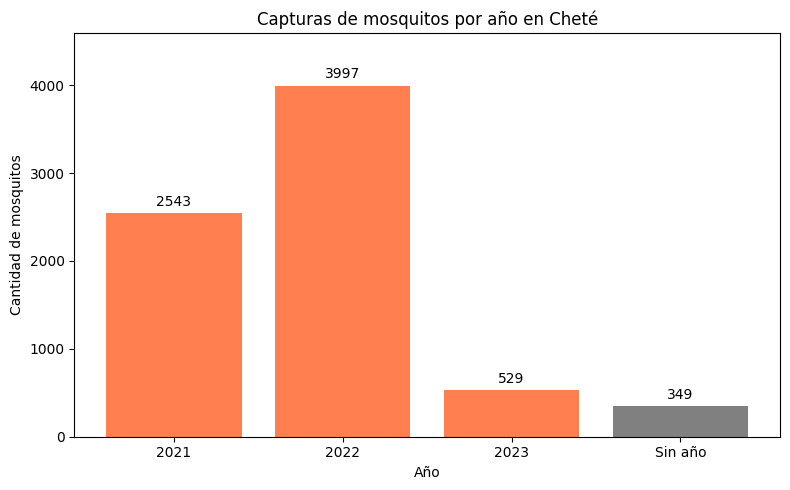

In [ ]:

import matplotlib.pyplot as plt

# Agrupar las capturas por año, incluyendo los datos faltantes
datos = df_chete.copy()
datos['anio_grafica'] = datos['year'].astype('string').fillna('Sin año')

por_anio = datos.groupby('anio_grafica')['individualCount'].sum()

# Ordenar los años y dejar "Sin año" al final
orden = ['2021', '2022', '2023', 'Sin año']
por_anio = por_anio.reindex(orden, fill_value=0)

# Crear la gráfica
plt.figure(figsize=(8, 5))

colores = ['coral', 'coral', 'coral', 'gray']
barras = plt.bar(por_anio.index, por_anio.values, color=colores)

# Mostrar los valores encima de cada barra
plt.bar_label(barras, padding=3)

plt.title('Capturas de mosquitos por año en Cheté')
plt.xlabel('Año')
plt.ylabel('Cantidad de mosquitos')
plt.ylim(0, por_anio.max() * 1.15)

plt.tight_layout()
plt.show()


In [ ]:

print("Total de mosquitos:", df_chete['individualCount'].sum())

print("\nCapturas por año:")
print(df_chete.groupby('year')['individualCount'].sum())

print("\nCapturas sin año:")
print(df_chete.loc[
    df_chete['year'].isna(), 'individualCount'
].sum())


Total de mosquitos: 7418

Capturas por año:
year
2021    2543
2022    3997
2023     529
Name: individualCount, dtype: int64

Capturas sin año:
349


### 2.3. Análisis exploratorio de los datos

A partir de los datos de Cheté, realizamos tres gráficas para observar cómo se distribuyen las capturas de mosquitos según la especie, la sublocalidad y el año.

**Gráfica 1. Capturas por especie:** Observamos que *Anopheles albimanus* es la especie predominante, con 7.287 mosquitos capturados, mientras que *Anopheles neivai* y *Anopheles apicimacula* presentan cantidades mucho menores, con 126 y 5 respectivamente. Esto evidencia una gran diferencia en la frecuencia de captura entre especies.

**Gráfica 2. Capturas por sublocalidad:** Encontramos que Cheté 1 registra una cantidad considerablemente mayor de mosquitos (6.047) que Cheté 2 (1.371). Esta diferencia podría estar relacionada con las condiciones de cada lugar o con el esfuerzo de muestreo realizado.

**Gráfica 3. Capturas por año:** Se observa que 2022 fue el año con más capturas registradas (3.997), seguido de 2021 (2.543) y 2023 (529). Sin embargo, encontramos que 349 mosquitos no tienen un año asignado, por lo que no aparecen en esta gráfica. Además, no podemos afirmar que las capturas hayan disminuido por una reducción de la población de mosquitos, ya que todavía no hemos ajustado los resultados según el esfuerzo de muestreo de cada año.

En general, estas gráficas nos permiten identificar diferencias importantes en las capturas según la especie, el lugar y el tiempo. No obstante, para realizar comparaciones más precisas sería necesario considerar las horas y noches de muestreo, ya que una mayor cantidad de capturas no necesariamente significa una mayor abundancia de mosquitos.

In [ ]:
# Calcular y mostrar los estadígrafos de las noches de muestreo en Cheté
print("=== ESTADÍGRAFOS DE LAS NOCHES DE MUESTREO EN CHETÉ ===")
display(df_chete[['noches_muestreo']].describe())

=== ESTADÍGRAFOS DE LAS NOCHES DE MUESTREO EN CHETÉ ===


,noches_muestreo
count,77.000000
mean,3.402597
std,1.016440
min,1.000000
25%,3.000000
50%,4.000000
75%,4.000000
max,6.000000


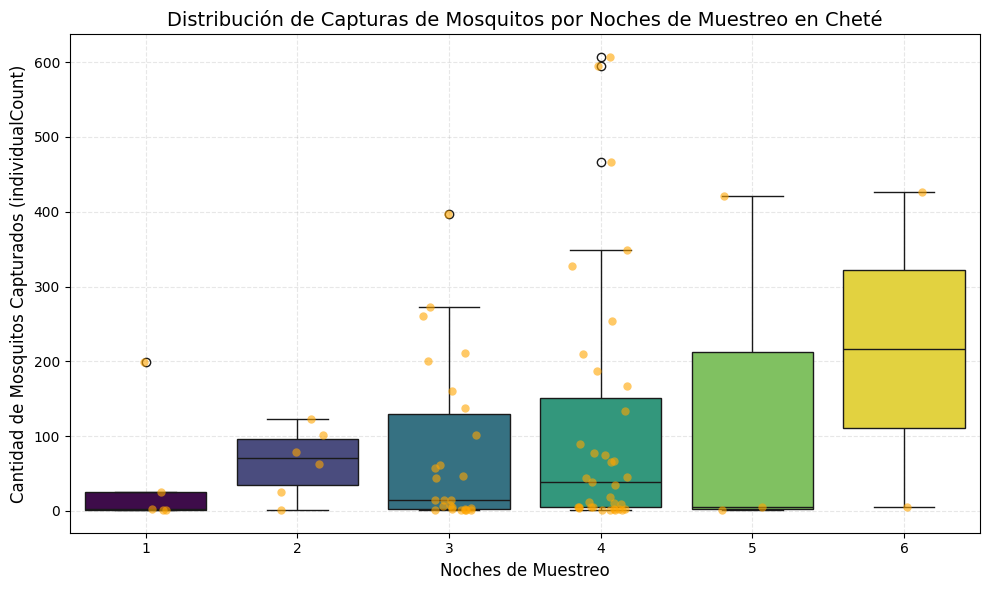

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Graficar un boxplot para ver la distribución de capturas por número de noches de muestreo
sns.boxplot(
    data=df_chete,
    x='noches_muestreo',
    y='individualCount',
    palette='viridis',
    hue='noches_muestreo',
    legend=False
)

# Añadir un stripplot encima para visualizar los puntos de datos individuales reales
sns.stripplot(
    data=df_chete,
    x='noches_muestreo',
    y='individualCount',
    color='orange',
    alpha=0.6,
    size=6,
    jitter=0.2
)

# Configurar títulos y etiquetas
plt.title('Distribución de Capturas de Mosquitos por Noches de Muestreo en Cheté', fontsize=14)
plt.xlabel('Noches de Muestreo', fontsize=12)
plt.ylabel('Cantidad de Mosquitos Capturados (individualCount)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Agrupar por noches de muestreo y mostrar estadísticas descriptivas de las capturas en Cheté
print("=== ESTADÍGRAFOS DE CAPTURAS POR NOCHES DE MUESTREO EN CHETÉ ===")
display(df_chete.groupby('noches_muestreo')['individualCount'].describe())

=== ESTADÍGRAFOS DE CAPTURAS POR NOCHES DE MUESTREO EN CHETÉ ===


,count,mean,std,min,25%,50%,75%,max
noches_muestreo,,,,,,,,
1,5.0,45.600000,86.364344,1.0,1.00,2.0,25.0,199.0
2,6.0,65.166667,46.058296,1.0,34.25,70.0,96.0,123.0
3,26.0,77.961538,108.364378,1.0,2.50,15.0,129.0,397.0
4,35.0,111.800000,167.655073,1.0,5.00,39.0,150.5,607.0
5,3.0,142.333333,241.340700,1.0,3.00,5.0,213.0,421.0
6,2.0,216.000000,298.399062,5.0,110.50,216.0,321.5,427.0


/tmp/ipykernel_1270/4078093321.py:27: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


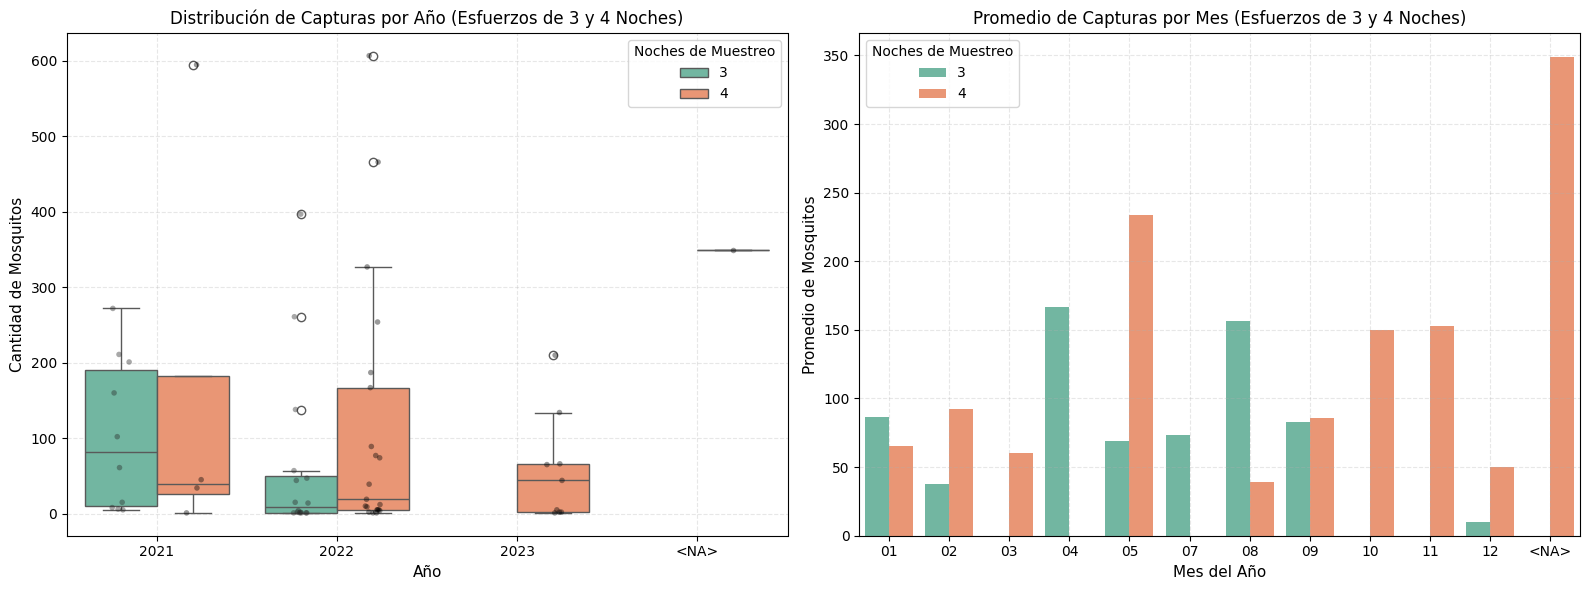

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Filtrar los datos de Cheté para quedarnos solo con campañas de 3 y 4 noches
df_filtrado = df_chete[df_chete['noches_muestreo'].isin([3, 4])].copy()

# Asegurar que el año y el mes estén en formatos limpios para graficar
df_filtrado['anio_label'] = df_filtrado['year'].astype(str).fillna('Sin año')
df_filtrado['mes_label'] = df_filtrado['month'].astype(str).str.zfill(2)

# Ordenar por mes cronológico
df_filtrado = df_filtrado.sort_values('month')

# 2. Crear panel con 2 visualizaciones
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico A: Comparativa por Año para 3 y 4 noches (Boxplot)
sns.boxplot(
    data=df_filtrado,
    x='anio_label',
    y='individualCount',
    hue='noches_muestreo',
    palette='Set2',
    ax=axes[0]
)
sns.stripplot(
    data=df_filtrado,
    x='anio_label',
    y='individualCount',
    hue='noches_muestreo',
    dodge=True,
    color='black',
    alpha=0.4,
    size=4,
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Distribución de Capturas por Año (Esfuerzos de 3 y 4 Noches)', fontsize=12)
axes[0].set_xlabel('Año', fontsize=11)
axes[0].set_ylabel('Cantidad de Mosquitos', fontsize=11)
axes[0].grid(True, linestyle='--', alpha=0.3)
axes[0].legend(title='Noches de Muestreo')

# Gráfico B: Comportamiento mensual (Tendencia o promedio por mes)
sns.barplot(
    data=df_filtrado,
    x='mes_label',
    y='individualCount',
    hue='noches_muestreo',
    palette='Set2',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Promedio de Capturas por Mes (Esfuerzos de 3 y 4 Noches)', fontsize=12)
axes[1].set_xlabel('Mes del Año', fontsize=11)
axes[1].set_ylabel('Promedio de Mosquitos', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.3)
axes[1].legend(title='Noches de Muestreo')

plt.tight_layout()
plt.show()

### 2.4. Comparación con nuestra estimación inicial de Fermi

En nuestra simulación de Fermi estimamos un promedio de aproximadamente **216 mosquitos durante cuatro noches**, considerando seis puestos de captura, seis horas de trabajo por noche y diferentes ritmos de captura en interiores y exteriores.

Al analizar los datos reales de Cheté, encontramos 7.418 mosquitos registrados en distintos periodos. Sin embargo, observamos que las condiciones del estudio no coinciden exactamente con nuestra simulación, pues los registros presentan diferentes duraciones y esfuerzos de muestreo.

Por esta razón, no podemos comparar directamente ambos totales. Para mejorar nuestra estimación, consideramos necesario calcular las tasas de captura reales y ajustarlas al escenario de cuatro noches que queremos predecir.

De esta manera, conservamos nuestra estimación inicial como referencia y utilizamos los datos reales para construir posteriormente un modelo más preciso.

Meses comparables: 21


verbatimLocality,Chete 1,Chete 2
periodo,,
2021-01,4.786,4.393
2021-02,2.786,3.643
2021-04,7.556,1.694
2021-05,4.444,1.042
2021-08,5.861,2.833
2021-09,0.222,0.167
2021-10,12.396,0.708
2021-11,5.931,0.938
2021-12,2.583,0.417


Estadístico: 3.0
Valor p: 0.0
Se rechaza H0: hay evidencia de diferencia.


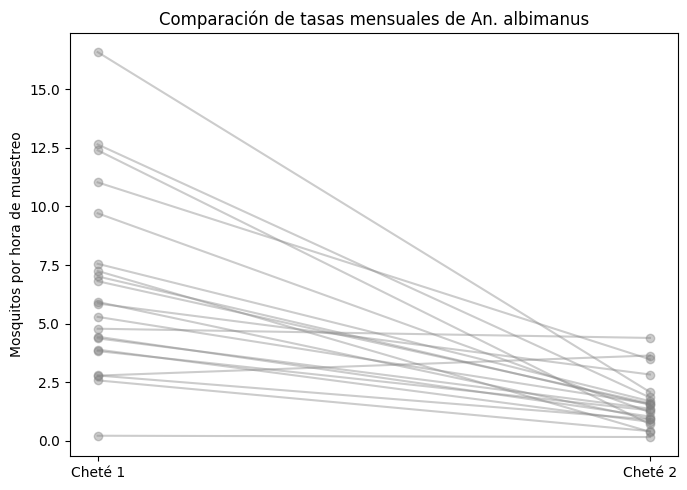

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# 1. Seleccionar Anopheles albimanus
datos = df_chete[
    df_chete['scientificName'] == 'Anopheles albimanus'
].copy()

# 2. Conservar registros con fecha y esfuerzo válidos
datos = datos.dropna(subset=[
    'year', 'month', 'individualCount',
    'esfuerzo_total_horas'
])

datos = datos[datos['esfuerzo_total_horas'] > 0]

# 3. Crear un identificador de año y mes
datos['periodo'] = (
    datos['year'].astype(int).astype(str) + '-' +
    datos['month'].astype(int).astype(str).str.zfill(2)
)

# 4. Agrupar capturas y horas por mes y sublocalidad
resumen = datos.groupby(
    ['periodo', 'verbatimLocality']
).agg(
    mosquitos=('individualCount', 'sum'),
    horas=('esfuerzo_total_horas', 'sum')
).reset_index()

# Tasa por hora de muestreo registrada
resumen['tasa'] = resumen['mosquitos'] / resumen['horas']

# 5. Emparejar los mismos meses
pares = resumen.pivot(
    index='periodo',
    columns='verbatimLocality',
    values='tasa'
).dropna(subset=['Chete 1', 'Chete 2'])

print("Meses comparables:", len(pares))
display(pares.round(3))

# 6. Prueba de Wilcoxon
if len(pares) >= 5:
    estadistico, p_valor = wilcoxon(
        pares['Chete 1'],
        pares['Chete 2']
    )

    print("Estadístico:", estadistico)
    print("Valor p:", round(p_valor, 5))

    if p_valor < 0.05:
        print("Se rechaza H0: hay evidencia de diferencia.")
    else:
        print("No se rechaza H0: evidencia insuficiente.")
else:
    print("Hay pocos meses comparables para esta prueba.")

# 7. Gráfica de las tasas emparejadas
plt.figure(figsize=(7, 5))

for _, fila in pares.iterrows():
    plt.plot(
        [1, 2],
        [fila['Chete 1'], fila['Chete 2']],
        '-o', color='gray', alpha=0.4
    )

plt.xticks([1, 2], ['Cheté 1', 'Cheté 2'])
plt.ylabel('Mosquitos por hora de muestreo')
plt.title('Comparación de tasas mensuales de An. albimanus')
plt.tight_layout()
plt.show()


### 2.5. Comprobación estadística de un hallazgo

A partir de las gráficas anteriores, decidimos comprobar si existía una diferencia significativa en las tasas de captura de *Anopheles albimanus* entre Cheté 1 y Cheté 2.

Para esto utilizamos la **prueba de Wilcoxon para muestras pareadas**, comparando las capturas por hora de ambas sublocalidades durante 21 meses en los que se tenían registros de las dos.

Los resultados mostraron que **Cheté 1 presentó tasas de captura superiores en 20 de los 21 meses analizados**. Además, obtuvimos un estadístico de 3,0 y un valor p menor a 0,001, por lo que rechazamos la hipótesis nula de igualdad de las tasas.

Esto sugiere que existe una diferencia estadísticamente significativa entre las tasas mensuales de captura registradas en ambas sublocalidades, siendo generalmente mayores en Cheté 1.

Sin embargo, debemos considerar que las capturas pueden estar influenciadas por las condiciones ambientales, las características de cada lugar y las posibles diferencias en el muestreo. Además, los meses consecutivos no necesariamente son independientes, por lo que interpretamos esta prueba como evidencia exploratoria y no como una conclusión definitiva.

### 3.1. Definición de nuestra predicción

Para esta etapa del proyecto, nuestro objetivo será **predecir la cantidad total de mosquitos *Anopheles* que podrían capturarse durante una próxima campaña de cuatro noches en Cheté**.

Esta predicción sería útil para que el equipo de entomología pueda planificar los materiales necesarios, como frascos de almacenamiento, y organizar mejor el personal y las horas de trabajo.

Partiremos de nuestra estimación inicial de Fermi, que arrojó un promedio de aproximadamente **216 mosquitos en cuatro noches**, y buscaremos mejorarla utilizando los registros reales del estudio.

Para ello, tendremos en cuenta variables como la fecha, la sublocalidad y el esfuerzo de muestreo. Además, no queremos obtener únicamente una cifra, sino también un rango que represente la incertidumbre de nuestra predicción.

Finalmente, consideraremos que nuestro modelo es útil si logra predecir las capturas con un error menor que el de una estimación sencilla basada en los datos históricos.

In [ ]:

# Revisar cómo se organizan los eventos de Cheté

print("Filas totales:", len(df_chete))
print("Eventos únicos:", df_chete['eventID'].nunique())

# Resumen por evento
revision = df_chete.groupby('eventID').agg(
    filas=('id', 'count'),
    especies=('scientificName', 'nunique'),
    esfuerzos_distintos=('samplingEffort', 'nunique'),
    fechas_distintas=('eventDate', 'nunique'),
    mosquitos=('individualCount', 'sum')
).reset_index()

print("\nPrimeros eventos:")
display(revision.head(15))

print("\nEventos con diferentes esfuerzos:")
display(
    revision[revision['esfuerzos_distintos'] > 1].head(15)
)

print("\nRegistros sin fecha de inicio:")
print(df_chete['fecha_inicio'].isna().sum())

print("\nRegistros sin esfuerzo calculado:")
print(df_chete['esfuerzo_total_horas'].isna().sum())


Filas totales: 77
Eventos únicos: 44

Primeros eventos:


,eventID,filas,especies,esfuerzos_distintos,fechas_distintas,mosquitos
0,Chete1-01,2,2,2,2,202
1,Chete1-02,1,1,1,1,78
2,Chete1-03,1,1,1,1,272
3,Chete1-04,1,1,1,1,160
4,Chete1-05,1,1,1,1,211
5,Chete1-06,1,1,1,1,8
6,Chete1-07,2,2,1,1,596
7,Chete1-08,2,2,1,1,432
8,Chete1-09,2,2,1,1,63
9,Chete1-10,2,2,1,1,255



Eventos con diferentes esfuerzos:


,eventID,filas,especies,esfuerzos_distintos,fechas_distintas,mosquitos
0,Chete1-01,2,2,2,2,202
22,Chete2-01,3,3,2,2,126



Registros sin fecha de inicio:
1

Registros sin esfuerzo calculado:
0


In [ ]:

# Revisar los dos eventos con inconsistencias
eventos_revisar = ['Chete1-01', 'Chete2-01']

columnas = [
    'eventID',
    'scientificName',
    'individualCount',
    'eventDate',
    'samplingEffort',
    'fecha_inicio',
    'fecha_fin'
]

print("=== EVENTOS CON DIFERENCIAS ===")

display(
    df_chete[
        df_chete['eventID'].isin(eventos_revisar)
    ][columnas].sort_values('eventID')
)

# Revisar registros sin fecha o año
print("\n=== REGISTROS SIN FECHA O AÑO ===")

display(
    df_chete[
        df_chete['fecha_inicio'].isna() |
        df_chete['year'].isna()
    ][columnas + ['year']]
)

# Verificar cantidad de eventos por año
print("\n=== EVENTOS ÚNICOS POR AÑO ===")

print(
    df_chete.groupby('year', dropna=False)['eventID']
    .nunique()
)


=== EVENTOS CON DIFERENCIAS ===


,eventID,scientificName,individualCount,eventDate,samplingEffort,fecha_inicio,fecha_fin
38,Chete1-01,Anopheles albimanus,201,2021-01-20/2021-01-27,"14 h por noche, 3 noches",2021-01-20,2021-01-27
40,Chete1-01,Anopheles neivai,1,2021-01-20,"14 h por noche, 1 noche",2021-01-20,2021-01-20
45,Chete2-01,Anopheles albimanus,123,2021-01-21/2021-01-28,"14 h por noche, 2 noches",2021-01-21,2021-01-28
60,Chete2-01,Anopheles apicimacula,1,2021-01-28,"14 h por noche, 1 noche",2021-01-28,2021-01-28
61,Chete2-01,Anopheles neivai,2,2021-01-28,"14 h por noche, 1 noche",2021-01-28,2021-01-28



=== REGISTROS SIN FECHA O AÑO ===


,eventID,scientificName,individualCount,eventDate,samplingEffort,fecha_inicio,fecha_fin,year
1307,Chete1-20,Anopheles albimanus,349,NaN,"12 h por noche, 4 noches",NaT,NaT,<NA>



=== EVENTOS ÚNICOS POR AÑO ===
year
2021    18
2022    20
2023     6
<NA>     1
Name: eventID, dtype: int64


In [ ]:

import pandas as pd

# Copiar los registros originales de Cheté
datos = df_chete.copy()

# Crear el año del evento
datos['anio_modelo'] = pd.to_numeric(
    datos['year'], errors='coerce'
).astype('Int64')

# Agrupar por evento y año
# Esto evita asignar automáticamente los registros sin fecha
df_eventos = datos.groupby(
    ['eventID', 'anio_modelo'],
    dropna=False
).agg(
    sublocalidad=('verbatimLocality', 'first'),
    fecha=('fecha_inicio', 'min'),
    total_mosquitos=('individualCount', 'sum'),
    noches=('noches_muestreo', 'max'),
    horas_por_noche=('horas_por_noche', 'max'),
    esfuerzo_horas=('esfuerzo_total_horas', 'max'),
    especies=('scientificName', 'nunique'),
    esfuerzos_distintos=('samplingEffort', 'nunique'),
    protocolos_distintos=('samplingProtocol', 'nunique'),
    habitats_distintos=('habitat', 'nunique')
).reset_index()

# Calcular tasa provisional por hora
df_eventos['tasa_captura'] = (
    df_eventos['total_mosquitos']
    / df_eventos['esfuerzo_horas']
)

print("=== DATAFRAME POR EVENTOS ===")
display(df_eventos.head(10))

print("\nTotal de unidades agrupadas:", len(df_eventos))

print("\n=== EVENTOS QUE REQUIEREN REVISIÓN ===")
display(
    df_eventos[
        (df_eventos['esfuerzos_distintos'] > 1) |
        (df_eventos['protocolos_distintos'] > 1) |
        (df_eventos['habitats_distintos'] > 1) |
        (df_eventos['fecha'].isna())
    ]
)

print("\n=== REGISTROS DE CHETE1-20 ===")
display(
    datos.loc[
        datos['eventID'] == 'Chete1-20',
        ['eventID', 'eventDate', 'year',
         'scientificName', 'individualCount',
         'samplingEffort']
    ]
)


=== DATAFRAME POR EVENTOS ===


,eventID,anio_modelo,sublocalidad,fecha,total_mosquitos,noches,horas_por_noche,esfuerzo_horas,especies,esfuerzos_distintos,protocolos_distintos,habitats_distintos,tasa_captura
0,Chete1-01,2021,Chete 1,2021-01-20,202,3,14,42,2,2,1,1,4.809524
1,Chete1-02,2021,Chete 1,2021-02-03,78,2,14,28,1,1,1,1,2.785714
2,Chete1-03,2021,Chete 1,2021-04-13,272,3,12,36,1,1,1,1,7.555556
3,Chete1-04,2021,Chete 1,2021-05-03,160,3,12,36,1,1,1,1,4.444444
4,Chete1-05,2021,Chete 1,2021-08-16,211,3,12,36,1,1,1,1,5.861111
5,Chete1-06,2021,Chete 1,2021-09-01,8,3,12,36,1,1,1,1,0.222222
6,Chete1-07,2021,Chete 1,2021-10-07,596,4,12,48,2,1,1,1,12.416667
7,Chete1-08,2021,Chete 1,2021-11-02,432,6,12,72,2,1,1,1,6.000000
8,Chete1-09,2021,Chete 1,2021-12-03,63,2,12,24,2,1,1,1,2.625000
9,Chete1-10,2022,Chete 1,2022-01-17,255,4,12,48,2,1,1,1,5.312500



Total de unidades agrupadas: 45

=== EVENTOS QUE REQUIEREN REVISIÓN ===


,eventID,anio_modelo,sublocalidad,fecha,total_mosquitos,noches,horas_por_noche,esfuerzo_horas,especies,esfuerzos_distintos,protocolos_distintos,habitats_distintos,tasa_captura
0,Chete1-01,2021,Chete 1,2021-01-20,202,3,14,42,2,2,1,1,4.809524
20,Chete1-20,<NA>,Chete 1,NaT,349,4,12,48,1,1,1,1,7.270833
23,Chete2-01,2021,Chete 2,2021-01-21,126,2,14,28,3,2,1,1,4.500000



=== REGISTROS DE CHETE1-20 ===


,eventID,eventDate,year,scientificName,individualCount,samplingEffort
1307,Chete1-20,NaN,<NA>,Anopheles albimanus,349,"12 h por noche, 4 noches"
1308,Chete1-20,2023-01-10/2023-01-25,2023,Anopheles neivai,5,"12 h por noche, 4 noches"


In [ ]:
import pandas as pd
import numpy as np

datos = df_chete.copy()

# Recuperar años faltantes usando otros registros del mismo evento
datos['anio_modelo'] = pd.to_numeric(
    datos['year'], errors='coerce'
).astype('Int64')

# Verificar que ningún evento tenga años contradictorios
assert (
    datos.groupby('eventID')['anio_modelo'].nunique() <= 1
).all(), "Hay eventos asociados a más de un año"

datos['anio_modelo'] = datos['anio_modelo'].fillna(
    datos.groupby('eventID')['anio_modelo'].transform('max')
)

# Elegir la fila de mayor esfuerzo por evento
# para no sumar las mismas horas entre especies
indices = datos.groupby('eventID')['esfuerzo_total_horas'].idxmax()

esfuerzos = datos.loc[
    indices,
    ['eventID', 'noches_muestreo',
     'horas_por_noche', 'esfuerzo_total_horas']
].copy()

# Unir capturas de especies del mismo evento
df_eventos = datos.groupby('eventID', as_index=False).agg(
    anio=('anio_modelo', 'max'),
    fecha=('fecha_inicio', 'min'),
    sublocalidad=('verbatimLocality', 'first'),
    total_mosquitos=('individualCount', 'sum')
)

df_eventos = df_eventos.merge(esfuerzos, on='eventID')

df_eventos = df_eventos.rename(columns={
    'noches_muestreo': 'noches',
    'esfuerzo_total_horas': 'esfuerzo_horas'
})

# Verificaciones
assert (df_eventos['esfuerzo_horas'] > 0).all()
assert df_eventos['total_mosquitos'].sum() == df_chete['individualCount'].sum()

print("Total de eventos:", len(df_eventos))
print("Total de mosquitos:", df_eventos['total_mosquitos'].sum())

display(df_eventos.head())


Total de eventos: 44
Total de mosquitos: 7418


,eventID,anio,fecha,sublocalidad,total_mosquitos,noches,horas_por_noche,esfuerzo_horas
0,Chete1-01,2021,2021-01-20,Chete 1,202,3,14,42
1,Chete1-02,2021,2021-02-03,Chete 1,78,2,14,28
2,Chete1-03,2021,2021-04-13,Chete 1,272,3,12,36
3,Chete1-04,2021,2021-05-03,Chete 1,160,3,12,36
4,Chete1-05,2021,2021-08-16,Chete 1,211,3,12,36


=== RESULTADOS DE VALIDACIÓN (2022) ===


,Modelo,MAE,RMSE
0,Historico,128.35,165.34
1,Poisson,73.42,113.77



Dispersión del modelo Poisson:
66.04


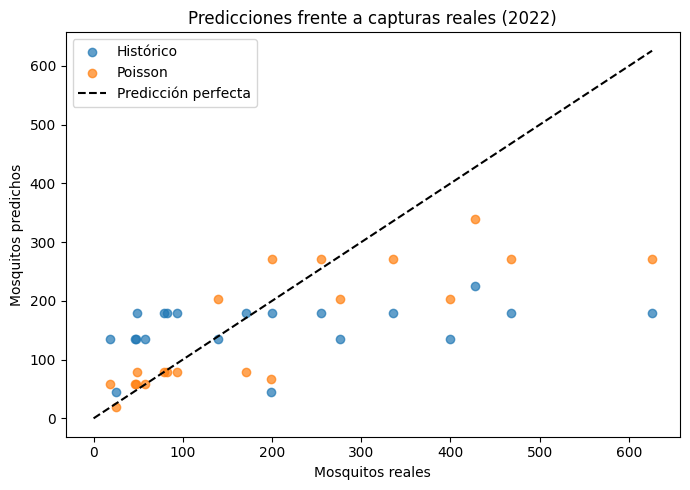

In [ ]:

import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Dividir temporalmente
entreno = df_eventos[df_eventos['anio'] == 2021].copy()
validacion = df_eventos[df_eventos['anio'] == 2022].copy()

# MODELO 1: referencia histórica
tasa_historica = (
    entreno['total_mosquitos'].sum()
    / entreno['esfuerzo_horas'].sum()
)

validacion['pred_historico'] = (
    tasa_historica * validacion['esfuerzo_horas']
)

# MODELO 2: regresión de Poisson
def preparar_X(df):
    X = pd.DataFrame({
        'es_chete2': (df['sublocalidad'] == 'Chete 2').astype(int)
    }, index=df.index)
    return sm.add_constant(X, has_constant='add')

X_entreno = preparar_X(entreno)
X_validacion = preparar_X(validacion)

modelo_poisson = sm.GLM(
    entreno['total_mosquitos'],
    X_entreno,
    family=sm.families.Poisson(),
    offset=np.log(entreno['esfuerzo_horas'])
).fit()

validacion['pred_poisson'] = modelo_poisson.predict(
    X_validacion,
    offset=np.log(validacion['esfuerzo_horas'])
)

# Evaluar en 2022
y_real = validacion['total_mosquitos']

resultados = []

for nombre, columna in [
    ('Historico', 'pred_historico'),
    ('Poisson', 'pred_poisson')
]:
    pred = validacion[columna]

    resultados.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_real, pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, pred))
    })

metricas = pd.DataFrame(resultados)

print("=== RESULTADOS DE VALIDACIÓN (2022) ===")
display(metricas.round(2))

print("\nDispersión del modelo Poisson:")
print(round(
    modelo_poisson.pearson_chi2 / modelo_poisson.df_resid, 2
))

# Comparación visual
plt.figure(figsize=(7, 5))

plt.scatter(y_real, validacion['pred_historico'],
            label='Histórico', alpha=0.7)

plt.scatter(y_real, validacion['pred_poisson'],
            label='Poisson', alpha=0.7)

limite = max(y_real.max(),
             validacion['pred_historico'].max(),
             validacion['pred_poisson'].max())

plt.plot([0, limite], [0, limite], 'k--',
         label='Predicción perfecta')

plt.title('Predicciones frente a capturas reales (2022)')
plt.xlabel('Mosquitos reales')
plt.ylabel('Mosquitos predichos')
plt.legend()
plt.tight_layout()
plt.show()


### 3.2. Construcción de modelos predictivos

Para predecir las capturas de mosquitos construimos tres modelos: uno basado en tasas históricas, una regresión de Poisson y una regresión binomial negativa. Utilizamos los registros de 2021 para entrenarlos y los de 2022 para comparar su desempeño, reservando 2023 para una evaluación posterior.

Los resultados mostraron que **la regresión de Poisson obtuvo el menor error**, con un MAE de 73,42 mosquitos, seguida de la binomial negativa con 78,44 y el modelo histórico con 128,35. Esto representa una mejora del 42,8 % de Poisson respecto al modelo más sencillo.

Sin embargo, encontramos que los datos presentan una variabilidad considerable, con un índice de dispersión de 66,04 para Poisson. Por esta razón, también probamos la binomial negativa, que logró ajustarse correctamente, aunque no superó a Poisson en precisión predictiva.

Por lo tanto, seleccionamos provisionalmente **la regresión de Poisson como nuestro modelo principal**, manteniendo la binomial negativa como alternativa para estudiar la incertidumbre de las predicciones.

=== COMPARACIÓN DE MODELOS (2022) ===


,Modelo,MAE,RMSE
0,Historico,128.35,165.34
1,Poisson,73.42,113.77
2,Binomial negativa,78.44,122.20



Parámetro de dispersión alpha:
0.6578

Convergencia del modelo:
True


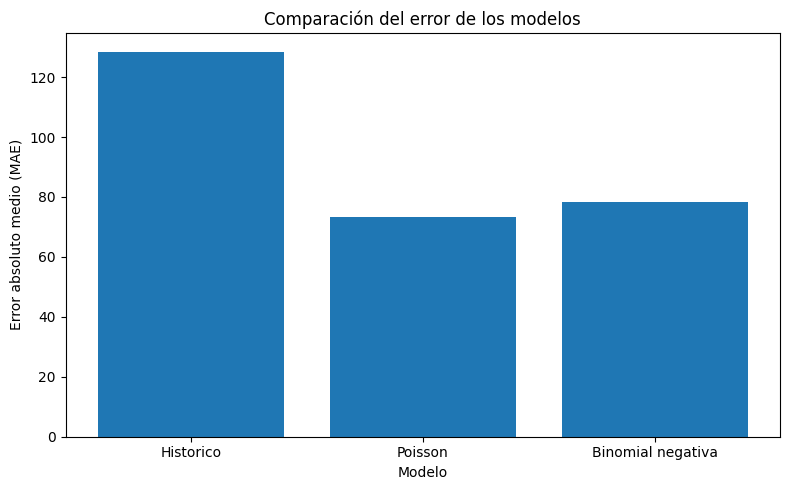

In [ ]:

import statsmodels.api as sm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Entrenar regresión binomial negativa
modelo_nb = sm.NegativeBinomial(
    entreno['total_mosquitos'],
    X_entreno,
    offset=np.log(entreno['esfuerzo_horas']),
    loglike_method='nb2'
).fit(disp=False, maxiter=200)

# 2. Predecir los eventos de 2022
validacion['pred_nb'] = modelo_nb.predict(
    X_validacion,
    offset=np.log(validacion['esfuerzo_horas'])
)

# 3. Comparar los tres modelos
resultados = []

modelos = {
    'Historico': 'pred_historico',
    'Poisson': 'pred_poisson',
    'Binomial negativa': 'pred_nb'
}

for nombre, columna in modelos.items():
    y_real = validacion['total_mosquitos']
    y_pred = validacion[columna]

    resultados.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred))
    })

comparacion = pd.DataFrame(resultados)

print("=== COMPARACIÓN DE MODELOS (2022) ===")
display(comparacion.round(2))

print("\nParámetro de dispersión alpha:")
print(round(modelo_nb.params['alpha'], 4))

print("\nConvergencia del modelo:")
print(modelo_nb.mle_retvals.get('converged'))

# 4. Gráfica comparativa del error
plt.figure(figsize=(8, 5))

plt.bar(comparacion['Modelo'], comparacion['MAE'])

plt.title('Comparación del error de los modelos')
plt.xlabel('Modelo')
plt.ylabel('Error absoluto medio (MAE)')

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Entrenar con 2021 y 2022
train_final = df_eventos[
    df_eventos['anio'].isin([2021, 2022])
].copy()

# Evaluar con 2023
test_final = df_eventos[
    df_eventos['anio'] == 2023
].copy()

# Verificaciones
assert len(test_final) > 0
assert (train_final['esfuerzo_horas'] > 0).all()
assert (test_final['esfuerzo_horas'] > 0).all()

# Modelo histórico
tasa = (
    train_final['total_mosquitos'].sum()
    / train_final['esfuerzo_horas'].sum()
)

test_final['pred_historico'] = (
    tasa * test_final['esfuerzo_horas']
)

# Regresión de Poisson
X_train = preparar_X(train_final)
X_test = preparar_X(test_final)

poisson_final = sm.GLM(
    train_final['total_mosquitos'],
    X_train,
    family=sm.families.Poisson(),
    offset=np.log(train_final['esfuerzo_horas'])
).fit()

test_final['pred_poisson'] = poisson_final.predict(
    X_test,
    offset=np.log(test_final['esfuerzo_horas'])
)

# Comparación de errores
resultados_finales = []

for nombre, columna in [
    ('Historico', 'pred_historico'),
    ('Poisson', 'pred_poisson')
]:
    real = test_final['total_mosquitos']
    pred = test_final[columna]

    resultados_finales.append({
        'Modelo': nombre,
        'MAE': mean_absolute_error(real, pred),
        'RMSE': np.sqrt(mean_squared_error(real, pred))
    })

print("=== EVALUACIÓN FINAL 2023 ===")
display(pd.DataFrame(resultados_finales).round(2))

print("\n=== PREDICCIONES POR EVENTO ===")
display(test_final[[
    'eventID',
    'sublocalidad',
    'total_mosquitos',
    'pred_historico',
    'pred_poisson'
]].round(2))


=== EVALUACIÓN FINAL 2023 ===


,Modelo,MAE,RMSE
0,Historico,111.75,125.43
1,Poisson,66.59,95.63



=== PREDICCIONES POR EVENTO ===


,eventID,sublocalidad,total_mosquitos,pred_historico,pred_poisson
19,Chete1-20,Chete 1,354,210.12,330.02
20,Chete1-21,Chete 1,210,210.12,330.02
21,Chete1-22,Chete 1,134,210.12,330.02
41,Chete2-20,Chete 2,67,210.12,79.84
42,Chete2-21,Chete 2,67,210.12,79.84
43,Chete2-22,Chete 2,46,210.12,79.84


### 3.3. Evaluación temporal del modelo

Para evaluar nuestro modelo, utilizamos los datos de 2021 y 2022 para su entrenamiento y reservamos los registros de 2023 para comprobar su capacidad predictiva.

Los resultados mostraron que **la regresión de Poisson mantuvo un mejor desempeño que el modelo histórico**, obteniendo un error absoluto medio (MAE) de 66,59 mosquitos, frente a 111,75 del modelo histórico. Esto representa una reducción del error de aproximadamente el 40,4 %.

Sin embargo, observamos que el modelo todavía presenta dificultades para predecir algunas capturas. Por ejemplo, para los seis eventos de 2023 predijo aproximadamente 1.230 mosquitos, mientras que el total observado fue de 878.

Por lo tanto, consideramos que Poisson es nuestro mejor modelo hasta el momento, aunque sus predicciones deben interpretarse con precaución. Además, la evaluación se realizó con solamente seis eventos y con visitas repetidas a las mismas sublocalidades, por lo que todavía existe incertidumbre sobre su desempeño en campañas futuras.

In [ ]:

# Revisar las condiciones de muestreo de 2023
columnas = [
    'eventID',
    'eventTime',
    'samplingEffort',
    'samplingProtocol',
    'habitat'
]

revision_2023 = df_chete[
    df_chete['eventID'].isin(test_final['eventID'])
][columnas].drop_duplicates()

display(revision_2023.sort_values('eventID'))


,eventID,eventTime,samplingEffort,samplingProtocol,habitat
1307,Chete1-20,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio
1376,Chete1-21,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio
1441,Chete1-22,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio
1309,Chete2-20,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio
1377,Chete2-21,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio
1442,Chete2-22,17:00:00/05:00:00,"12 h por noche, 4 noches",Aspirador bucal | Colecta con cebo humano,En domicilio


### 3.4. Predicción de la próxima campaña

Para realizar nuestra predicción, tomamos como referencia las condiciones de muestreo observadas en 2023, donde se registraron campañas de cuatro noches con 12 horas de captura por noche.

Utilizando nuestro modelo de regresión de Poisson, entrenado con los datos de 2021 y 2022, estimamos aproximadamente **330 mosquitos en Cheté 1 y 80 en Cheté 2**, para un total esperado de **410 mosquitos** si se realiza un evento de muestreo en cada sublocalidad bajo condiciones similares.

Sin embargo, como anteriormente encontramos una variabilidad considerable en las capturas, consideramos importante acompañar esta predicción con un intervalo de incertidumbre. Para ello, utilizaremos una distribución binomial negativa que permita representar una mayor variabilidad que la distribución de Poisson.

=== PREDICCIÓN POR SUBLOCALIDAD ===


,sublocalidad,esfuerzo_horas,prediccion
0,Chete 1,48,330.015424
1,Chete 2,48,79.843575


Total esperado: 409.86
Convergencia: True
Alpha: 0.442

=== RESULTADOS ===
Predicción central: 410
Intervalo predictivo 90 %: 127 - 841


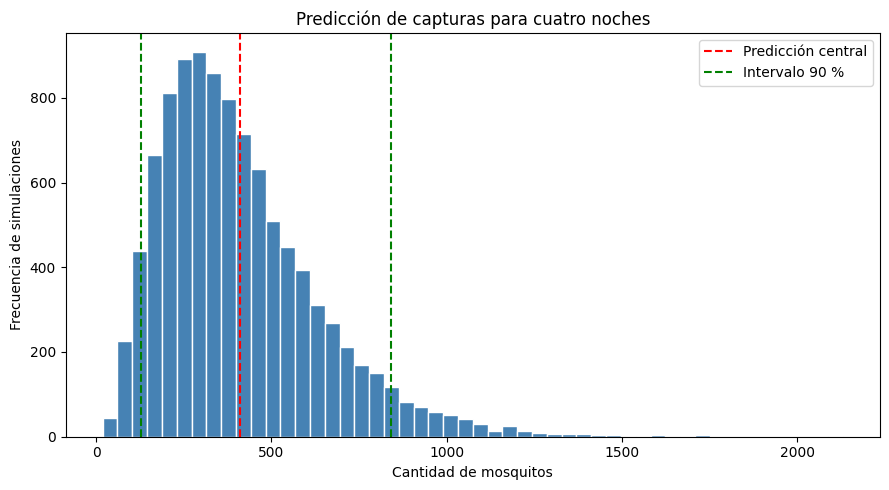

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# 1. Definir la próxima campaña
proxima = pd.DataFrame({
    'sublocalidad': ['Chete 1', 'Chete 2'],
    'esfuerzo_horas': [48, 48]
})

# 2. Predecir con nuestro modelo Poisson final
X_proxima = preparar_X(proxima)

proxima['prediccion'] = poisson_final.predict(
    X_proxima,
    offset=np.log(proxima['esfuerzo_horas'])
)

print("=== PREDICCIÓN POR SUBLOCALIDAD ===")
display(proxima)

print("Total esperado:",
      round(proxima['prediccion'].sum(), 2))

# 3. Estimar la dispersión usando solo 2021 y 2022
modelo_dispersion = sm.NegativeBinomial(
    train_final['total_mosquitos'],
    X_train,
    offset=np.log(train_final['esfuerzo_horas']),
    loglike_method='nb2'
).fit(disp=False, maxiter=300)

print("Convergencia:",
      modelo_dispersion.mle_retvals.get('converged'))

alpha = float(modelo_dispersion.params['alpha'])
print("Alpha:", round(alpha, 4))

# 4. Simular posibles resultados futuros
if not modelo_dispersion.mle_retvals.get('converged'):
    raise ValueError("Revisar ajuste de binomial negativa")

if not np.isfinite(alpha) or alpha <= 0:
    raise ValueError("Parámetro alpha no válido")

np.random.seed(42)
M = 10000

simulaciones = np.zeros(M)

for media in proxima['prediccion']:
    n = 1 / alpha
    p = n / (n + media)

    simulaciones += np.random.negative_binomial(
        n, p, size=M
    )

# 5. Calcular intervalo predictivo del 90 %
inferior = np.percentile(simulaciones, 5)
superior = np.percentile(simulaciones, 95)

print("\n=== RESULTADOS ===")
print("Predicción central:",
      round(proxima['prediccion'].sum()))
print("Intervalo predictivo 90 %:",
      round(inferior), "-", round(superior))

# 6. Visualizar resultados
plt.figure(figsize=(9, 5))

plt.hist(simulaciones, bins=50,
         color='steelblue', edgecolor='white')

plt.axvline(proxima['prediccion'].sum(),
            color='red', linestyle='--',
            label='Predicción central')

plt.axvline(inferior, color='green',
            linestyle='--', label='Intervalo 90 %')

plt.axvline(superior, color='green',
            linestyle='--')

plt.title('Predicción de capturas para cuatro noches')
plt.xlabel('Cantidad de mosquitos')
plt.ylabel('Frecuencia de simulaciones')
plt.legend()
plt.tight_layout()
plt.show()


### 3.4. Predicción de la próxima campaña con incertidumbre

Para realizar nuestra predicción final, consideramos una campaña de cuatro noches con 12 horas de muestreo por noche, utilizando condiciones similares a las registradas en 2023.

Con nuestro modelo de regresión de Poisson obtuvimos una predicción de aproximadamente **330 mosquitos en Cheté 1 y 80 en Cheté 2**, para un total esperado de **410 mosquitos** entre ambas sublocalidades.

Sin embargo, debido a la alta variabilidad encontrada en los datos, realizamos 10.000 simulaciones utilizando una distribución binomial negativa, con un parámetro de dispersión de 0,442. Esto nos permitió obtener un **intervalo predictivo del 90 % entre 127 y 841 mosquitos**.

La gráfica muestra que, aunque esperamos capturar alrededor de 410 mosquitos, también existe la posibilidad de obtener cantidades considerablemente mayores o menores. Esto demuestra la importancia de considerar la incertidumbre al planificar los recursos necesarios.

Finalmente, concluimos que nuestro modelo puede ser útil para organizar futuras campañas, ya que presentó mejores resultados que la referencia histórica. Sin embargo, el amplio intervalo predictivo indica que todavía existe una incertidumbre importante, por lo que recomendamos planificar los materiales considerando también escenarios de capturas elevadas.

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Cantidad de mosquitos por especie y sublocalidad
tabla_especies = df_chete.pivot_table(
    index='verbatimLocality',
    columns='scientificName',
    values='individualCount',
    aggfunc='sum',
    fill_value=0
)

# Calcular porcentajes por sublocalidad
porcentajes = tabla_especies.div(
    tabla_especies.sum(axis=1), axis=0
) * 100

print("=== CANTIDAD DE MOSQUITOS ===")
display(tabla_especies)

print("\n=== PORCENTAJE POR ESPECIE ===")
display(porcentajes.round(2))


=== CANTIDAD DE MOSQUITOS ===


scientificName,Anopheles albimanus,Anopheles apicimacula,Anopheles neivai
verbatimLocality,,,
Chete 1,5964,4,79
Chete 2,1323,1,47



=== PORCENTAJE POR ESPECIE ===


scientificName,Anopheles albimanus,Anopheles apicimacula,Anopheles neivai
verbatimLocality,,,
Chete 1,98.63,0.07,1.31
Chete 2,96.50,0.07,3.43


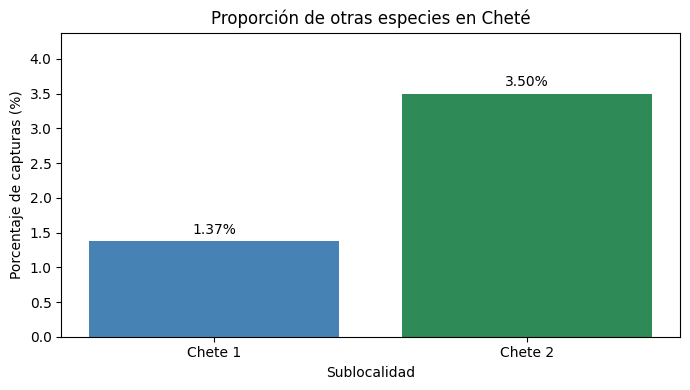

In [ ]:

# Porcentaje de especies distintas de An. albimanus
otras_especies = (
    100 - porcentajes['Anopheles albimanus']
)

plt.figure(figsize=(7, 4))

barras = plt.bar(
    otras_especies.index,
    otras_especies.values,
    color=['steelblue', 'seagreen']
)

plt.bar_label(barras, fmt='%.2f%%', padding=3)

plt.title('Proporción de otras especies en Cheté')
plt.xlabel('Sublocalidad')
plt.ylabel('Porcentaje de capturas (%)')
plt.ylim(0, otras_especies.max() * 1.25)

plt.tight_layout()
plt.show()


### 4. Lo que nos preguntamos en campo

**¿La composición de especies de mosquitos Anopheles es diferente entre Cheté 1 y Cheté 2?**

Para responder esta pregunta, analizamos la cantidad y proporción de las diferentes especies de mosquitos registradas en ambas sublocalidades.

Los resultados mostraron que *Anopheles albimanus* fue la especie predominante en ambos lugares, representando el **98,63 % de las capturas en Cheté 1 y el 96,50 % en Cheté 2**. Sin embargo, encontramos que Cheté 2 presentó una mayor proporción de otras especies (3,50 %) en comparación con Cheté 1 (1,37 %).

Esta diferencia se debe principalmente a *Anopheles neivai*, que representó el 3,43 % de las capturas en Cheté 2, frente al 1,31 % en Cheté 1. Por otro lado, *Anopheles apicimacula* presentó una proporción muy pequeña y similar en ambos lugares.

En conclusión, **aunque Cheté 1 registró una mayor cantidad total de mosquitos, Cheté 2 presentó una proporción ligeramente mayor de especies distintas de Anopheles albimanus**. Esto sugiere posibles diferencias en la composición de especies entre ambas sublocalidades, aunque sería necesario realizar análisis adicionales para determinar si estas diferencias son estadísticamente significativas.